# 01 · Preprocessing — Gao 2021 Breast Cancer (malignant compartment)

Isolate malignant cells, integrate patients (Harmony), embed, remove detached islands, and
split the manifold into transcriptional lobes. Every tunable choice is **derived from this
dataset**, not inherited from the Puram anchor. Deliverable: `processed.h5ad`, `samples.pdf`.

**Leaf decision (data-driven).** Gao et al. deposit two overlapping matrix leaves under
`Data_Gao2021_Breast`: `/Breast` (DCIS1 + TNBC1–3) and `/Breast_and_thyroid` (ATC1–5 +
TNBC4–5). The two leaves hold **disjoint samples** that together make the 11 in the summary.
The `/Breast_and_thyroid` leaf is dominated by **anaplastic thyroid carcinoma** (ATC, 5 samples,
5,592 malignant cells) — a *different tissue and lineage* that would confound a breast
malignant-cell manifold. But its TNBC4/TNBC5 (3,896 cells) are legitimate breast malignant
cells. So we scope to **breast only** (cancer_type ∈ {Breast Cancer, Premalignant}) and **pool
the six breast samples across both leaves** on their shared gene universe — recovering the full
breast cohort rather than discarding TNBC4/5 by using `/Breast` alone. The five ATC (thyroid)
samples are excluded.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Gao2021_Breast | category: Breast


### Load malignant compartment — pool the breast samples across both leaves
Gao et al. annotate `cell_type` directly; we take their `Malignant` calls. Because the breast
samples are split across two matrix leaves with **different gene universes**, we load both,
keep only breast-sample malignant cells, and concatenate on the **shared gene intersection**
(module-gene coverage is near-complete in both leaves). Every sample lives entirely in one leaf,
so Harmony on `sample` (below) also absorbs any residual leaf-of-origin batch.

In [3]:
import anndata as ad
smp = pd.read_csv(os.path.join(pth_in, 'Samples.csv'), dtype=str)
breast_samples = set(smp.loc[smp.cancer_type.isin(['Breast Cancer','Premalignant']), 'sample'])
print('breast samples (thyroid ATC excluded):', sorted(breast_samples))

leaves = [d for d in sorted(os.listdir(pth_in)) if os.path.isdir(os.path.join(pth_in, d))]
parts = []
for leaf in leaves:
    a = load_CCCA_adata(os.path.join(pth_in, leaf), verbose=False)
    a = a[(a.obs.celltype == 'Malignant') & (a.obs['sample'].isin(breast_samples))].copy()
    if a.n_obs:
        print(f'  {leaf}: {a.n_obs} malignant breast cells, samples {sorted(a.obs["sample"].unique())}')
        parts.append(a)
common = sorted(set(parts[0].var_names).intersection(*[set(p.var_names) for p in parts[1:]]))
parts = [p[:, common].copy() for p in parts]
adata = ad.concat(parts, join='inner', merge='same'); adata.obs_names_make_unique()
print('pooled malignant breast:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| shared genes:', len(common))
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

breast samples (thyroid ATC excluded): ['DCIS1', 'TNBC1', 'TNBC2', 'TNBC3', 'TNBC4', 'TNBC5']
  Breast: 2710 malignant breast cells, samples ['DCIS1', 'TNBC1', 'TNBC2', 'TNBC3']
  Breast_and_thyroid: 3896 malignant breast cells, samples ['TNBC4', 'TNBC5']
pooled malignant breast: (6606, 22164) | samples: 6 | shared genes: 22164
expression: X max 9.29 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span an order of magnitude. Rather than a round-number cut, we find
the largest **multiplicative** cliff in the sorted counts and cut at its geometric mean — the
natural separatrix between well-sampled tumours and thin ones.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells | dropped:', sorted(set(n.index)-set(keep)))

sorted per-sample counts: [2647 1249 1101  796  618  195]
largest gap: 618 -> 195 (ratio 3.17)
derived threshold (geometric mean across the gap) = 347
kept 5/6 samples -> 6411 cells | dropped: ['TNBC3']


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing): we take
the strongest integration past which mixing plateaus. PC count (20) and UMAP spread (1.3) follow
the 10x precedents (Kürten/Sun/Lee, comparable cell counts).

*Determinism note:* Harmony's KMeans initialisation is not seed-deterministic, so the
same-sample fractions and cell counts below can shift by a few cells/±0.01 between runs; the
Gate-1 decision (one continuous, sample-mixed manifold) is robust to that tolerance.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2663 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2663
same-sample neighbour fraction | pre-Harmony 0.998 | sweep {2: 0.881, 5: 0.759, 10: 0.746}
selected theta = 10 (mixing plateaus; strongest integration without collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous arm termini.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('retained', adata.shape[0], 'cells on the main component')

removed 89 cells in 1 detached islands
retained 6322 cells on the main component


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers the transcriptional lobes. We label them *by biology*:
the compartment with the **lower cycling fraction** is the **Embryonic** candidate; the highly
cycling one is **Cycling/Metabolic**. `cell_cycle_phase` comes from the publication's phase calls.
Whether the trajectory is scoped to one lobe or spans all is decided in 02 from the signature
geography, not assumed here.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
lab_map = {l: ('Cycling/Metabolic' if l==cyc.idxmax() else 'Embryonic')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 3788, '2': 1080, '3': 1063, '1': 391}
cycling fraction per lobe: {'0': 0.081, '1': 0.046, '2': 0.557, '3': 0.052}
compartments: {'Embryonic': 5242, 'Cycling/Metabolic': 1080}


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one **continuous** manifold. The read is made
on the **regenerated embedding itself** (not a scalar alone): the deliverable `samples.pdf`
below shows every sample sharing one connected cloud, corroborated by the theta sweep (mixing
improves monotonically to plateau) and a single kNN connected component after island removal.

5 samples share one continuous manifold; kNN graph connected components = 1.
theta sweep drove same-sample neighbour fraction downward to a plateau (strong mixing).
Gate 1: samples intermixed on one continuous manifold -> GO


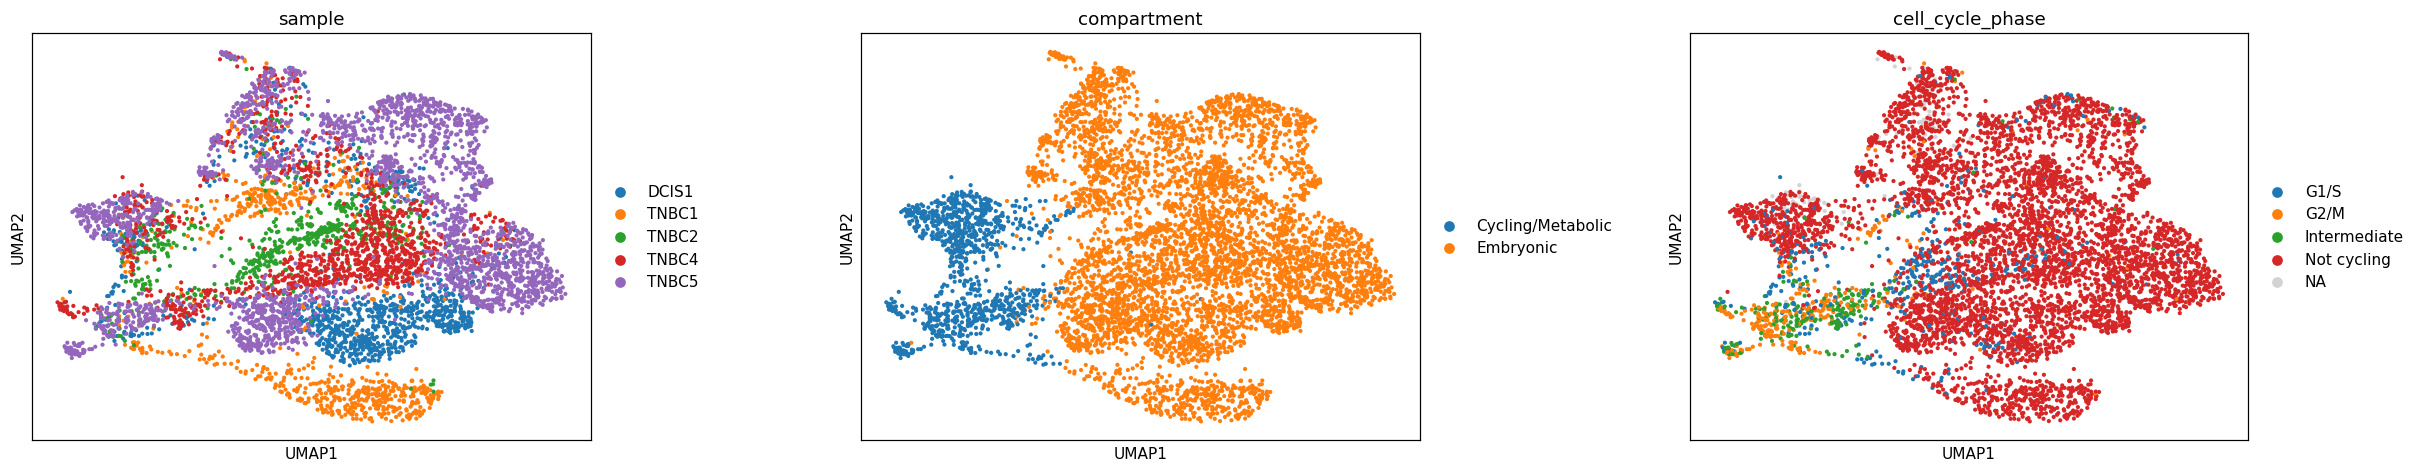

In [8]:
from scipy.sparse.csgraph import connected_components as _cc
ncomp_knn, _ = _cc(adata.obsp['connectivities'], directed=False)
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; kNN graph connected components = {ncomp_knn}.')
print('theta sweep drove same-sample neighbour fraction downward to a plateau (strong mixing).')
fig = sc.pl.umap(adata, color=['sample','compartment','cell_cycle_phase'],
                 size=30, wspace=.35, show=False)
print('Gate 1: samples intermixed on one continuous manifold -> GO')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (6322, 18061)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 6322


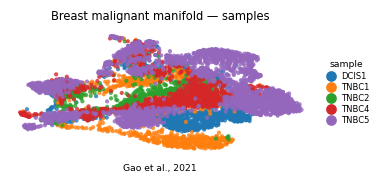

In [10]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30) to match every
# other trajectory panel. Colour = sample: intermixing across the cloud is the Gate-1 evidence.
# Orientation is set to the house convention (pseudotime left->right) in 02; here the raw
# embedding is shown (direction immaterial for this categorical panel).
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])